# Configurações Iniciais

In [14]:
"""
Treinamento de uma unidade D-RAMZI para aproximar y = x^2.


1. O estado estacionario dos portadores e resolvido pela equacao algebrica
   equivalente as EDOs, eliminando milhares de integracoes solve_ivp.
2. A curva D-RAMZI e avaliada vetorialmente para todos os valores de x.
3. As inicializacoes sao distribuidas por Sobol, em vez de sorteio bruto.
4. Cada inicializacao e refinada por least_squares com Trust Region Reflective.
5. A loss usada no treinamento e suave e invariante a uma escala positiva de
   potencia. A MSE antiga, baseada em y/max(y), tambem e reportada.
6. O melhor ponto visitado por cada start e sempre preservado. Portanto,
   o historico best-so-far nunca aumenta.

O modelo optico e o modelo estacionario dos portadores sao os mesmos do codigo
original. A mudanca e numerica/algoritmica, nao uma troca por surrogate.
"""

from __future__ import annotations

import csv
import json
import math
import time
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import scienceplots
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.stats import qmc


SEED = 42

N_TRAIN = 61 # 61 pontos deixam a forma da curva mais bem determinada que os 30 originais.
N_VALIDATION = 501 # 501 pontos para validação do aprendizado economiza mais tempo que treinar com 501 pontos.

# Cada start faz uma otimizacao local de verdade; nao e apenas amostrado.
N_STARTS = 30
MAX_NFEV_PER_START = 300

# Configuracao das diferencas finitas internas do least_squares.
DIFF_STEP = 1e-5
FTOL = 1e-10
XTOL = 1e-10
GTOL = 1e-10

SUCCESS_THRESHOLDS = (1e-2, 5e-3, 1e-3, 5e-4, 1e-4, 1e-5) # Limiares apenas para relatorio.

VALIDATE_STEADY_STATE = False # Validacao opcional contra a integracao temporal original. 

# Graficos e arquivos de saida.
SHOW_PLOTS = True
RUN_PARAMETER_SENSITIVITY = True
N_SENSITIVITY = 150

OUTPUT_DIR = Path("dramzi_trust_region_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Parâmetros Físicos

In [15]:
# ============================================================
# 2. PARAMETROS FISICOS
# ============================================================

lambda0 = 1550e-9
neff0 = 2.3537
ng = 2.3537

FSR_nm = 20e-9
L = lambda0**2 / (ng * FSR_nm)

L_rr_1 = 2.0 * L
L_rr_2 = 2.0 * L

L_wvg1 = 4.0 * L
L_wvg2 = 50e-6 + 2.0 * L
L_wvg3 = 50e-6

L_wvg4 = 4.0 * L
L_wvg5 = 50e-6
L_wvg6 = 50e-6 + 2.0 * L

alpha1 = 0.80
alpha2 = 0.80

eta_fc = 1e-6
gamma = 1e10
mu = 1e5
tau = 5e-9
xi = 1e40

delta_f = 2e9
delta_omega = 2.0 * np.pi * delta_f

P_max = 0.2e-3

r_coupler = 1.0 / np.sqrt(2.0)
t_coupler = np.sqrt(1.0 - r_coupler**2)

parameter_names = ("phi_1a", "phi_1b", "phi_2a", "phi_2b", "G_SOA")

theta_min = np.array([0.0, 0.0, 0.0, 0.0, 1.0], dtype=float)
theta_max = np.array([2.0 * np.pi, 2.0 * np.pi, 2.0 * np.pi, 2.0 * np.pi, 20.0],dtype=float)


# Funções Ópticas

In [16]:

def beta_calc(lamb_vector: np.ndarray | float) -> np.ndarray:
    lamb_vector = np.asarray(lamb_vector, dtype=float)
    dneff_dlambda = (neff0 - ng) / lambda0
    neff = neff0 + dneff_dlambda * (lamb_vector - lambda0)
    return 2.0 * np.pi * neff / lamb_vector


def beta_mrr(lamb_vector: np.ndarray | float, Nc: np.ndarray | float) -> np.ndarray:
    lamb_vector = np.asarray(lamb_vector, dtype=float)
    Nc = np.asarray(Nc, dtype=float)
    dneff_dlambda = (neff0 - ng) / lambda0
    neff = neff0 + dneff_dlambda * (lamb_vector - lambda0) - eta_fc * Nc
    return 2.0 * np.pi * neff / lamb_vector


def mrr_transfer(Nc: np.ndarray | float,ring_length: float,attenuation: float,) -> np.ndarray:
    beta = beta_mrr(lambda0, Nc)
    round_trip = np.exp(-1j * beta * ring_length)
    numerator = np.conj(r_coupler) - attenuation * round_trip
    denominator = 1.0 - r_coupler * attenuation * round_trip
    return numerator / denominator


def wvg_transfer(length: float) -> complex:
    beta = float(beta_calc(lambda0))
    return np.exp(-1j * beta * length)


H_wvg1 = wvg_transfer(L_wvg1)
H_wvg2 = wvg_transfer(L_wvg2)
H_wvg3 = wvg_transfer(L_wvg3)
H_wvg4 = wvg_transfer(L_wvg4)
H_wvg5 = wvg_transfer(L_wvg5)
H_wvg6 = wvg_transfer(L_wvg6)



# EDO original e Solução Estacionária Algébrica

O sistema de EDO's é dado por:

\begin{equation}
\frac{da}{dt}=-(j\Delta\omega + \gamma_L)a - j\eta_{fc}N_c a - j\mu\sqrt{P_{in}}
\end{equation}

\begin{equation}
\frac{dN_c}{dt}=\xi|a|^4-\frac{N_c}{\tau_{fc}}
\end{equation}

No regime estacionário $\frac{d}{dt}=0$, logo:

\begin{equation}
f(N_c) = N_c - \frac{A}{(\gamma_L^2+(\Delta\omega+\eta_{fc}N_c)^2)^2}, \text{onde } A = \tau_{fc} \xi \mu^4 P_{in}^2
\end{equation}

Queremos achar $N_c$ de tal forma que $f(N_c) = 0$. Sabendo que $\Delta\omega+\eta_{fc}N_c\ge\Delta\omega$, podemos escolher $\frac{A}{(\gamma_L^2+\Delta\omega^2)}$ como um possível zero da função. Utilizo o método de Newton-Raphson que consiste em:

\begin{equation}
N_{c_{k+1}}=N_{c_{k}}-\frac{f(N_{c_{k}})}{f'(N_{c_{k}})}
\end{equation}

Em até 12 iterações já é possível obter um valor de $N_c$ tal que $f(N_c)\approx 0$. $f'(N_{c_{k}})$ é:

\begin{equation}
f'(N_{c_{k}}) = 1+ \frac{4A\eta_{fc}(\Delta\omega+\eta_{fc}N_c)}{(\gamma_L^2+(\Delta\omega+\eta_{fc}N_c)^2)^3} 
\end{equation}

In [17]:
def carrier_dynamics(t: float,state: np.ndarray,Pin: float,detuning: float,) -> list[float]:
    a_real, a_imag, Nc = state
    a_cav = a_real + 1j * a_imag
    intensity = np.abs(a_cav) ** 2

    da_dt = (-(1j * detuning + gamma) * a_cav- 1j * eta_fc * Nc * a_cav- 1j * mu * np.sqrt(Pin))
    dNc_dt = -Nc / tau + xi * intensity**2

    return [float(da_dt.real), float(da_dt.imag), float(dNc_dt)]


def get_Nc_ss_ode(Pin: float, detuning: float = delta_omega) -> float:
    """Referencia lenta usada apenas para validacao opcional."""
    Pin = float(Pin)
    if Pin <= 0.0:
        return 0.0

    sol = solve_ivp(lambda t, y: carrier_dynamics(t, y, Pin, detuning),(0.0, 100e-9),[0.0, 0.0, 0.0],rtol=1e-9,atol=[1e-20, 1e-20, 1e-14],method="DOP853",)

    if not sol.success:
        raise RuntimeError(f"Falha na integracao dos portadores: {sol.message}")

    return float(sol.y[2, -1])


def get_Nc_ss(Pin: np.ndarray | float,detuning: float = delta_omega,newton_iterations: int = 12,) -> np.ndarray | float:
    Pin_array = np.asarray(Pin, dtype=float)
    scalar_input = Pin_array.ndim == 0
    P = np.atleast_1d(np.maximum(Pin_array, 0.0))

    A = tau * xi * (mu**4) * (P**2)
    base_denominator = gamma**2 + detuning**2

    # Para detuning positivo e eta_fc >= 0, esse eh um limite superior natural.
    upper = A / (base_denominator**2)
    Nc = upper.copy()

    for _ in range(newton_iterations):
        shifted_detuning = detuning + eta_fc * Nc
        denominator = gamma**2 + shifted_detuning**2

        function_value = Nc - A / (denominator**2)
        derivative = (1.0+ 4.0* A* eta_fc* shifted_detuning/ (denominator**3))

        proposal = Nc - function_value / derivative
        Nc = np.clip(proposal, 0.0, upper)

    Nc[P <= 0.0] = 0.0

    if scalar_input:
        return float(Nc[0])
    return Nc


def validate_steady_state_solver() -> None:
    powers = np.array([0.0, 0.05e-3, 0.10e-3, 0.20e-3])

    print("\n" + "=" * 78)
    print("VALIDACAO: ESTADO ESTACIONARIO ALGEBRICO VS ODE")
    print("=" * 78)

    for power in powers:
        algebraic = get_Nc_ss(power)
        ode = get_Nc_ss_ode(power)
        absolute_error = abs(algebraic - ode)
        relative_error = absolute_error / max(abs(ode), 1e-30)

        print(
            f"Pin={power:.3e} W | "
            f"Nc_ODE={ode:.9e} | "
            f"Nc_alg={algebraic:.9e} | "
            f"erro_rel={relative_error:.3e}"
        )



# Estrutura completa do D-RAMZI

In [18]:
def canonicalize_theta(theta: np.ndarray) -> np.ndarray:
    theta = np.asarray(theta, dtype=float).copy()
    theta[:4] = np.mod(theta[:4], 2.0 * np.pi)
    theta[4] = np.clip(theta[4], theta_min[4], theta_max[4])
    return theta


def dramzi_power_curve(
    x: np.ndarray,
    theta: np.ndarray,
    Nc1_cache: np.ndarray | None = None,
) -> np.ndarray:
    """
    Pout(x) para todos os pontos de x.

    A expressao abaixo eh a multiplicacao matricial original escrita por bracos,
    para vec_lamb = [lambda0].
    """
    x = np.asarray(x, dtype=float)
    theta = canonicalize_theta(theta)
    phi_1a, phi_1b, phi_2a, phi_2b, G_SOA = theta

    Pin = np.clip(x, 0.0, 1.0) * P_max
    Ein = np.sqrt(Pin).astype(complex)

    if Nc1_cache is None:
        Nc1 = get_Nc_ss(Pin)
    else:
        Nc1 = np.asarray(Nc1_cache, dtype=float)
        if Nc1.shape != Pin.shape:
            raise ValueError("Nc1_cache deve ter a mesma forma de x.")

    # -------------------- RAMZI 1 --------------------
    arm_top = mrr_transfer(Nc1, L_rr_1, alpha1) * Ein / np.sqrt(2.0)
    arm_bottom = H_wvg1 * Ein / np.sqrt(2.0)
    arm_bottom *= np.exp(1j * phi_1a)

    after_coupler_top = r_coupler * arm_top - 1j * t_coupler * arm_bottom
    after_coupler_bottom = -1j * t_coupler * arm_top + r_coupler * arm_bottom

    arm_top = H_wvg2 * after_coupler_top
    arm_bottom = H_wvg3 * after_coupler_bottom * np.exp(1j * phi_1b)

    E1 = (arm_top + arm_bottom) / np.sqrt(2.0)

    # ---------------------- SOA ----------------------
    E2 = np.sqrt(G_SOA) * E1
    Pin2 = np.abs(E2) ** 2

    # -------------------- RAMZI 2 --------------------
    Nc2 = get_Nc_ss(Pin2)

    arm_top = mrr_transfer(Nc2, L_rr_2, alpha2) * E2 / np.sqrt(2.0)
    arm_bottom = H_wvg4 * E2 / np.sqrt(2.0)
    arm_bottom *= np.exp(1j * phi_2a)

    after_coupler_top = r_coupler * arm_top - 1j * t_coupler * arm_bottom
    after_coupler_bottom = -1j * t_coupler * arm_top + r_coupler * arm_bottom

    arm_top = H_wvg5 * after_coupler_top
    arm_bottom = H_wvg6 * after_coupler_bottom * np.exp(1j * phi_2b)

    Eout = (arm_top + arm_bottom) / np.sqrt(2.0)
    return np.abs(Eout) ** 2

# Inicializações

0.39960147218350167 0.42629854615009366
0.6666482394240997 0.6459777621117037
0.333334 0.33507846949821635
0.5 0.5000000000883491
0.7080729871137708 0.7078066294284182
0.5865916255815551 0.5889533255249269


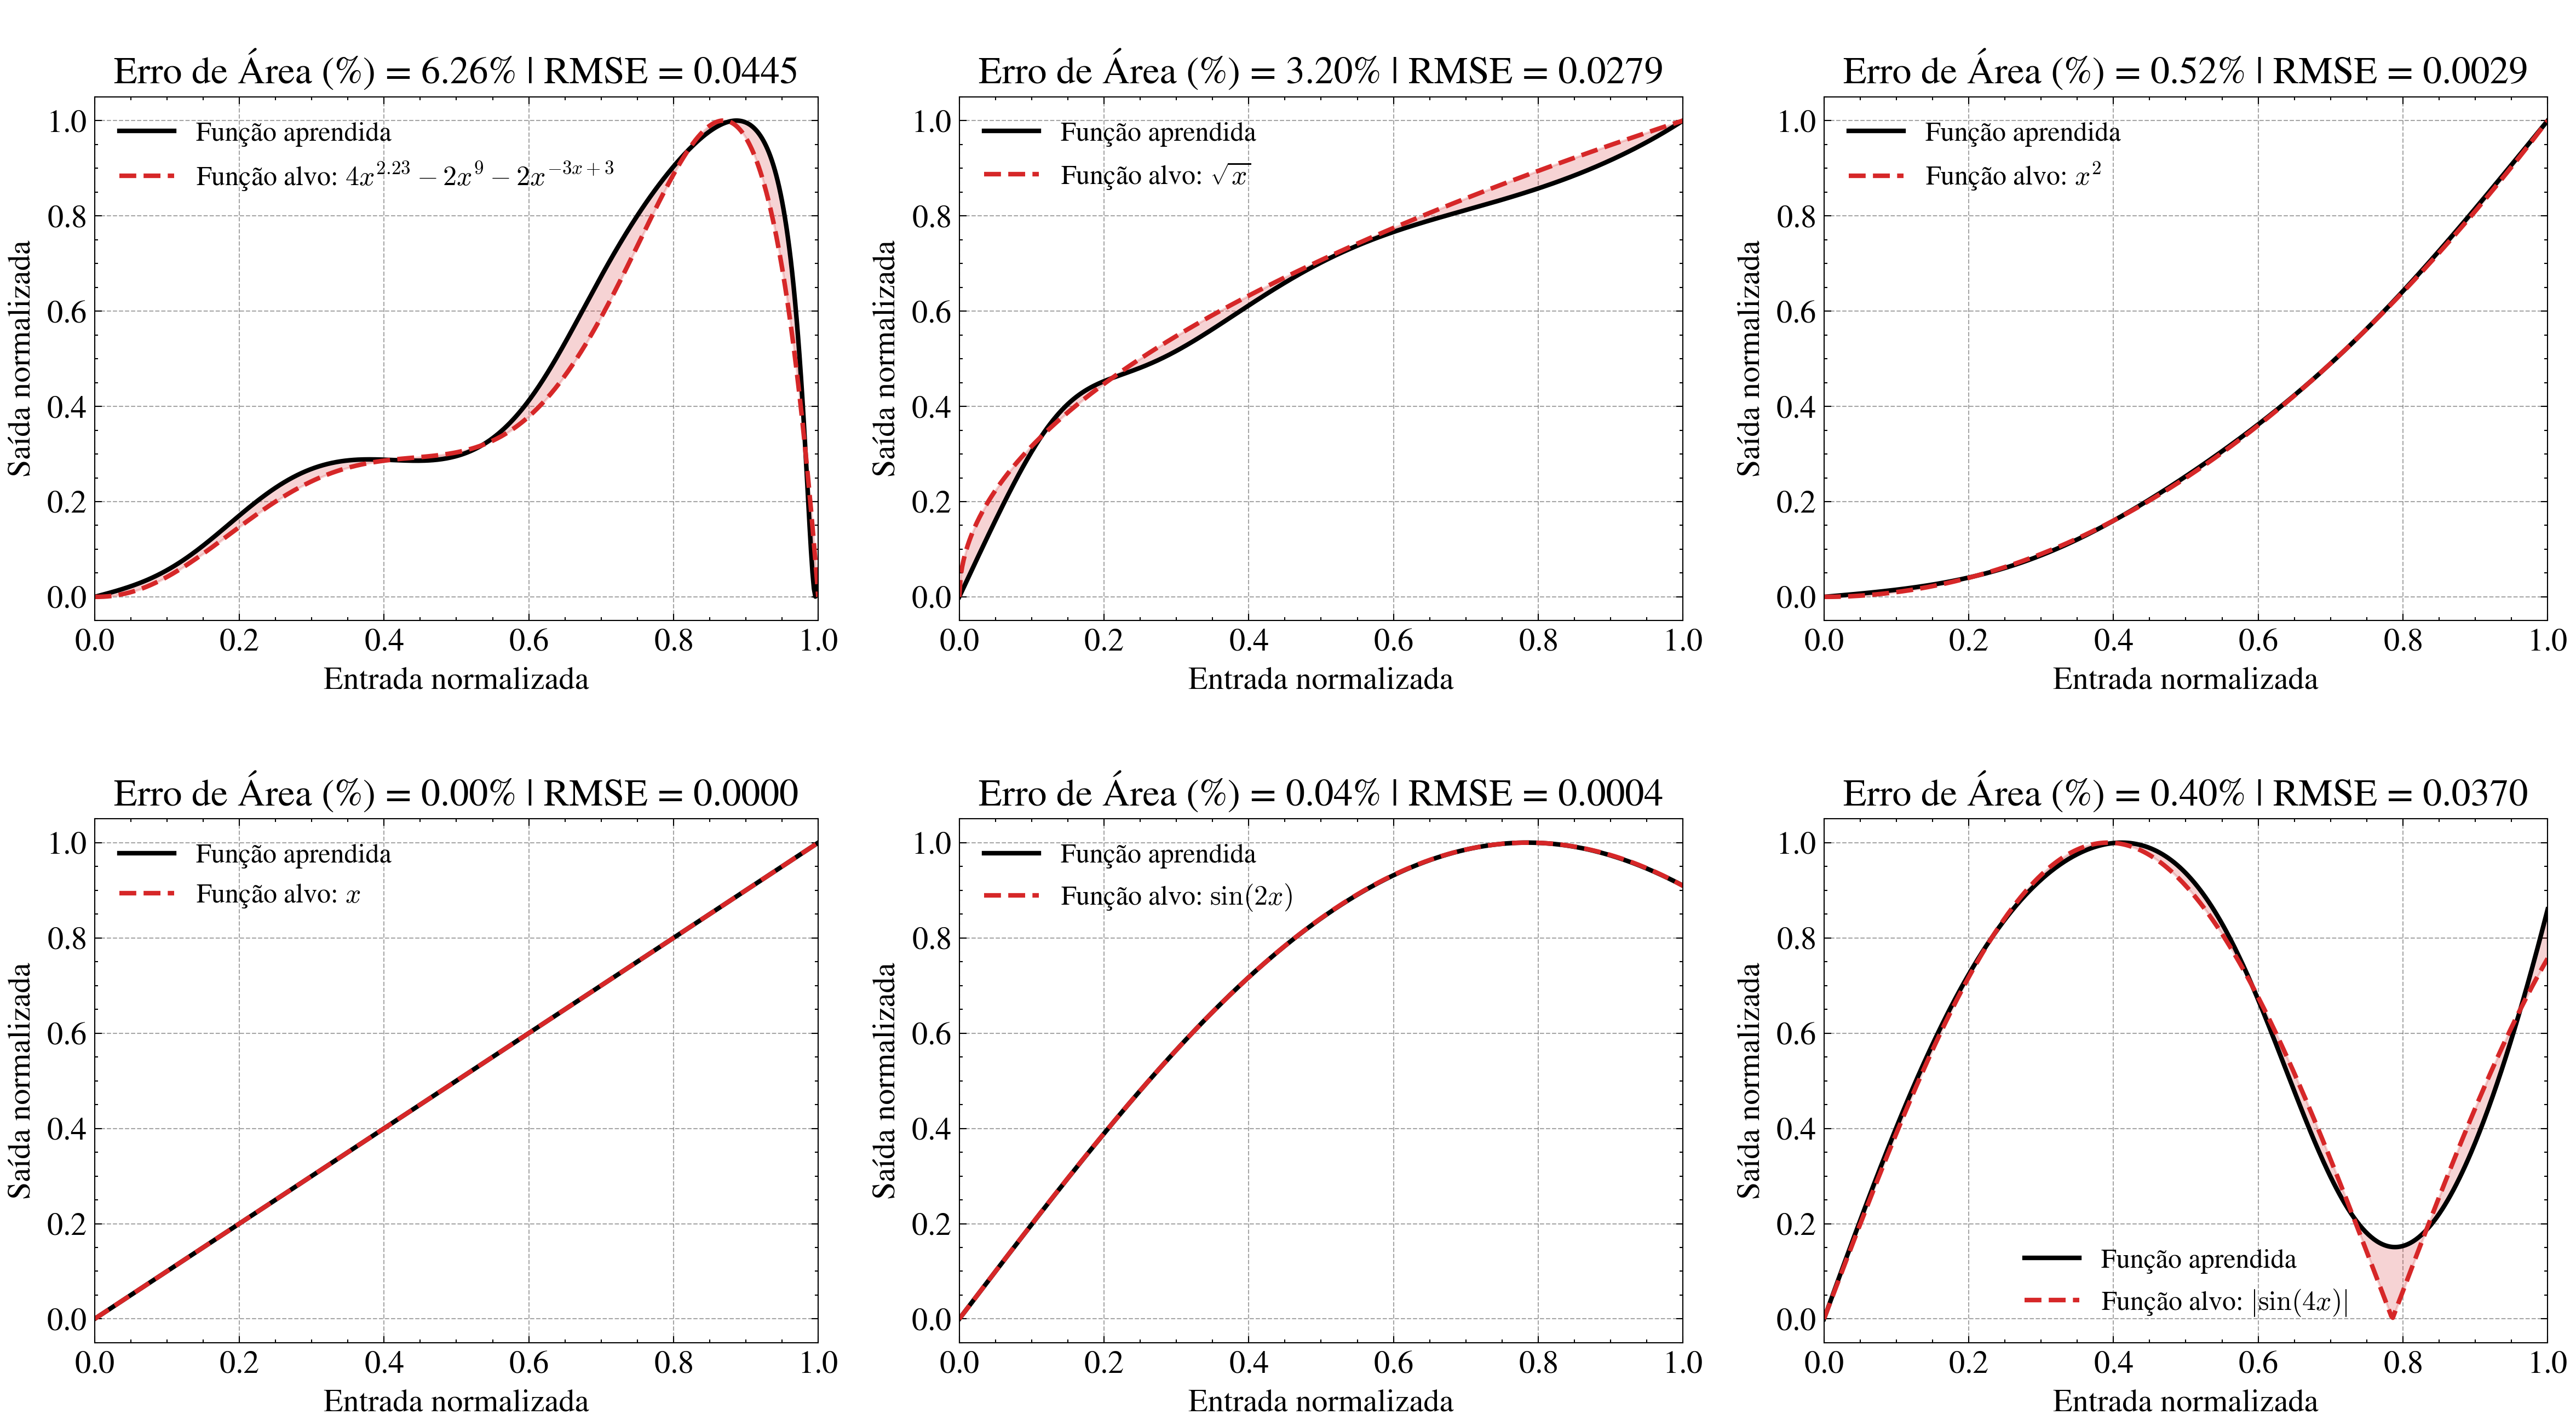

In [19]:
# Parâmetros de cada curva
casos = [
    {
        "nome": r"$4x^{2.23}-2x^9-2x^{-3x+3}$",
        "theta": [4.611894840, 3.500890349, 1.482964980, 2.478434865, 6.851815308],
        "funcao": lambda x: 4*x**2.23 - 2*x**9 - 2*x**(-3*x + 3),
    },
    {
        "nome": r"$\sqrt{x}$",
        "theta": [3.092808767, 0.697880546, 6.203921548, 2.446298849, 16.460361064],
        "funcao": lambda x: np.sqrt(x),
    },
    {
        "nome": r"$x^2$",
        "theta": [3.066376305, 0.797166696, 5.031894654, 0.895401939, 5.730379784],
        "funcao": lambda x: x**2,
    },
    {
        "nome": r"$x$",
        # Corrigido o nome duplicado: phi_1a = 1.530375048
        "theta": [1.530375048, 4.712388980, 1.057056719, 4.712388980, 5.922531599],
        "funcao": lambda x: x,
    },
    {
        "nome": r"$\sin(2x)$",
        "theta": [2.387733014, 4.759082434, 5.574046180, 3.395308636, 1.000000000],
        "funcao": lambda x: np.sin(2*x),
    },
    {
        "nome": r"$|\sin(4x)|$",
        "theta": [4.064455189, 4.167687078, 5.544323364, 3.221208754, 2.272681130],
        "funcao": lambda x: np.abs(np.sin(4*x)),
    },
]

x_validation = np.linspace(0.0, 1.0, N_VALIDATION)
Nc1_validation_cache = get_Nc_ss(x_validation * P_max)

with plt.style.context(["science", "ieee", "grid", "no-latex"]):
    plt.rcParams.update({
        "font.size": 14,         # fonte global
        # "axes.titlesize": 14,    # títulos
        # "axes.labelsize": 13,    # rótulos dos eixos
        # "xtick.labelsize": 11,   # valores do eixo x
        # "ytick.labelsize": 11,   # valores do eixo y
        "legend.fontsize": 12,   # legenda
    })
    fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=300)
    axes = axes.ravel()

    for ax, caso in zip(axes, casos):
        y_target = caso["funcao"](x_validation)
        P_out = dramzi_power_curve(
            x_validation,
            caso["theta"],
            Nc1_validation_cache
        )

        # Normaliza as curvas para comparação
        y_target_norm = y_target / np.max(y_target)
        y_learned_norm = P_out / np.max(P_out)

        # Integrais das funções normalizadas
        integral_target = np.trapezoid(y_target_norm, x_validation)
        integral_learned = np.trapezoid(y_learned_norm, x_validation)
        print(integral_target,integral_learned)
        # Erro percentual entre as integrais
        erro_percentual = (
            abs(integral_target - integral_learned)
            / abs(integral_learned)
            * 100
        )
        rmse = np.sqrt(np.mean((y_learned_norm - y_target_norm)**2))

        ax.plot(
            x_validation,
            y_learned_norm,
            color="black",
            linewidth=2,
            label="Função aprendida",
        )
        ax.plot(
            x_validation,
            y_target_norm,
            color="tab:red",
            linewidth=2,
            linestyle="--",
            label=f"Função alvo: {caso['nome']}",
        )
        ax.fill_between(
            x_validation,
            y_learned_norm,
            y_target_norm,
            color="tab:red",
            alpha=0.2,
        )

        ax.set_title(f"\nErro de Área (%) = {erro_percentual:.2f}% | RMSE = {rmse:.4f}")
        ax.set_xlabel("Entrada normalizada")
        ax.set_ylabel("Saída normalizada")
        ax.set_xlim(0, 1)
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(frameon=False)

    fig.tight_layout()
    plt.show()

In [20]:
x_train = np.linspace(0.0, 1.0, N_TRAIN) #N_TRAIN = 61
y_train = x_train**12
Nc1_train_cache = get_Nc_ss(x_train * P_max)

x_validation = np.linspace(0.0, 1.0, N_VALIDATION) #N_VALIDATION = 501
y_validation = x_validation**12
Nc1_validation_cache = get_Nc_ss(x_validation * P_max)

In [21]:
def optimal_positive_scale(raw_output: np.ndarray, target: np.ndarray) -> float:
    """Melhor s >= 0 para minimizar mean((s * raw_output - target)^2)."""
    raw_output = np.asarray(raw_output, dtype=float)
    target = np.asarray(target, dtype=float)

    denominator = float(np.dot(raw_output, raw_output))
    if denominator < 1e-40 or not np.isfinite(denominator):
        return 0.0

    scale = float(np.dot(raw_output, target) / denominator)
    return max(scale, 0.0)


def scaled_prediction(x: np.ndarray,target: np.ndarray,theta: np.ndarray,Nc1_cache: np.ndarray | None,) -> tuple[np.ndarray, np.ndarray, float]:
    raw_output = dramzi_power_curve(x, theta, Nc1_cache=Nc1_cache)
    scale = optimal_positive_scale(raw_output, target)
    prediction = scale * raw_output
    return prediction, raw_output, scale


def residual_vector(theta: np.ndarray) -> np.ndarray:
    try:
        prediction, _, _ = scaled_prediction(
            x_train,
            y_train,
            theta,
            Nc1_train_cache,
        )
        residual = prediction - y_train
    except (FloatingPointError, RuntimeError, ValueError):
        return np.full_like(y_train, 1e3)

    if not np.all(np.isfinite(residual)):
        return np.full_like(y_train, 1e3)

    return residual


def shape_mse(theta: np.ndarray) -> float:
    residual = residual_vector(theta)
    return float(np.mean(residual**2))


def legacy_max_normalized_mse(theta: np.ndarray,x: np.ndarray,target: np.ndarray,Nc1_cache: np.ndarray,) -> float:
    raw_output = dramzi_power_curve(x, theta, Nc1_cache=Nc1_cache)
    maximum = float(np.max(np.abs(raw_output)))

    if maximum < 1e-40:
        return 1e6

    normalized_output = raw_output / maximum
    return float(np.mean((normalized_output - target) ** 2))




# Tracker

**ResidualTracker** é um objeto que guarda:
1) A sequência de erros para cada start em **evaluation_mse**.
2) Histórico dos melhores erros em **best_mse_history** até a iteração atual. Isso evita a perda do melhor resultado, visto que o algoritmo pode sair de um erro bom para um erro ruim.
3) Após realizar todas as iterações para um start, o **best_mse** é a última posição do **best_mse_history**
4) Os parâmetros que fornecem os menores resíduos (melhores erros) são guardados em **best_theta**

Esse objeto será chamado em uma função chamada **optimize_one_start**. Sempre que uma iteração for feita, o objeto é chamado e atualiza todos os valores citados acima.

**StartResult** é uma classe que armazena todos os parâmetros de aprendizado para um único start.

Em suma, são objetos de monitoramento do aprendizado.

In [22]:
class ResidualTracker:
    def __init__(self) -> None:
        self.evaluation_mse: list[float] = []
        self.best_mse_history: list[float] = []
        self.best_mse = np.inf
        self.best_theta: np.ndarray | None = None

    def __call__(self, theta: np.ndarray) -> np.ndarray:
        residual = residual_vector(theta)
        mse = float(np.mean(residual**2))

        self.evaluation_mse.append(mse)

        if mse < self.best_mse:
            self.best_mse = mse
            self.best_theta = np.asarray(theta, dtype=float).copy()

        self.best_mse_history.append(self.best_mse)
        return residual


@dataclass
class StartResult:
    start: int
    theta_initial: np.ndarray
    initial_mse: float
    theta_best: np.ndarray
    final_mse: float
    solver_mse: float
    nfev_reported: int
    objective_calls: int
    optimality: float
    status: int
    message: str
    best_history: np.ndarray



# Inicializações SOBOL + Trust Region Reflective

* **make_sobol_initializations**:

    O método **Sobol** gera os valores iniciais dos cinco parâmetros de cada start de maneira mais uniforme pelo espaço de busca. Ao todo, são solicitadas 30 inicializações. Para gerar essa quantidade, calcula-se a menor potência de 2 que seja maior ou igual a 30: $(2^5 = 32)$. O **sampler** é configurado com d=5, pois cada inicialização contém cinco parâmetros: $(\phi_{1a}), (\phi_{1b}), (\phi_{2a}), (\phi_{2b})$ e $(G_{\mathrm{SOA}})$. A **seed** fixa torna a sequência reproduzível.

    Em seguida, **random_base2** gera 32 pontos Sobol, cada um com cinco valores. O código utiliza os 30 primeiros como inicializações e descarta os dois restantes. Cada inicialização é então convertida para os limites reais dos parâmetros ($0\le\phi_{(1,2)\times(a,b)}\le2\pi$ e $0\le G_{SOA}\le 20$).

    Cada start executa uma otimização, limitada a até 300 avaliações da função de erro, onde o solver pode parar antes desse limite caso os critérios de tolerância sejam atendidos.

* **optimize_one_start**:

    A função optimize_one_start executa a otimização para uma inicialização específica. Ela recebe o índice do start e os valores iniciais dos cinco parâmetros, theta_initial. 
    1) Calcula o erro inicial e cria um **ResidualTracker**, que registra os erros e os parâmetros avaliados durante a busca.

    2) o **least_squares** ajusta os parâmetros para reduzir os resíduos entre a saída prevista pelo D‑RAMZI e a função alvo. A busca respeita os limites definidos em theta_min e theta_max, usa o método trf e estima numericamente como os resíduos variam quando os parâmetros são alterados. A otimização pode parar quando os critérios de tolerância são atendidos ou quando alcança o limite de avaliações definido por MAX_NFEV_PER_START.

    3) a função compara o erro do ponto final do solver com o menor erro registrado pelo **ResidualTracker** e seleciona o melhor resultado. Por fim, retorna um objeto StartResult com os parâmetros iniciais e finais, os erros, o histórico da busca e informações sobre a convergência dessa inicialização.

In [23]:
# ============================================================
# 8. INICIALIZACOES SOBOL + TRUST REGION REFLECTIVE
# ============================================================

def make_sobol_initializations(n_starts: int, seed: int) -> np.ndarray:
    """Pontos de cobertura uniforme e reprodutivel no hipercubo [0,1]^5."""
    exponent = int(math.ceil(math.log2(max(n_starts, 1))))
    sampler = qmc.Sobol(d=5, scramble=True, seed=seed)
    unit_points = sampler.random_base2(m=exponent)[:n_starts]
    return theta_min + unit_points * (theta_max - theta_min)


def optimize_one_start(start_index: int, theta_initial: np.ndarray) -> StartResult:
    tracker = ResidualTracker()
    initial_mse = shape_mse(theta_initial)

    result = least_squares(
        tracker,
        x0=theta_initial,
        bounds=(theta_min, theta_max),
        method="trf", #Trust region reflective: o algoritmo monta uma aproximacao local do problema usando a jacobiana dos residuos e decide um passo dentro de uma regiao de confianca. Ainda pode convergir para um minimo local dependendo da inicializacao
        jac="2-point", #A jacobiana nao eh obtida analiticamente e sim numericamente, por meio da diferença de dois pontos. 
        x_scale="jac", #Significa como vou escalar os parâmetros durante a otimização. Pode ser que um parametro seja mais sensivel que outro parametro.
        diff_step=DIFF_STEP, #passo numerico da "2-point"
        ftol=FTOL,
        xtol=XTOL,
        gtol=GTOL,
        max_nfev=MAX_NFEV_PER_START,
        verbose=0,
    )

    solver_mse = float(np.mean(result.fun**2))

    # Inclui explicitamente o ponto final do solver na disputa.
    if solver_mse < tracker.best_mse or tracker.best_theta is None:
        theta_best = np.asarray(result.x, dtype=float).copy()
        final_mse = solver_mse
    else:
        theta_best = tracker.best_theta.copy()
        final_mse = float(tracker.best_mse)

    return StartResult(
        start=start_index,
        theta_initial=np.asarray(theta_initial, dtype=float).copy(),
        initial_mse=initial_mse,
        theta_best=canonicalize_theta(theta_best),
        final_mse=final_mse,
        solver_mse=solver_mse,
        nfev_reported=int(result.nfev),
        objective_calls=len(tracker.evaluation_mse),
        optimality=float(result.optimality),
        status=int(result.status),
        message=str(result.message),
        best_history=np.asarray(tracker.best_mse_history, dtype=float),
    )



# Gráficos

In [24]:
def finish_plot(fig, filename: str) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")

    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


def plot_all_histories(results: list[StartResult], best_index: int) -> None:
    with plt.style.context(["science", "ieee", "grid", "no-latex"]):
        plt.rcParams.update({
                "font.size": 14,         # fonte global
            })
        fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

        colors = plt.cm.viridis(np.linspace(0.12, 0.88, len(results)))

        for index, result in enumerate(results):
            history = np.asarray(result.best_history, dtype=float)
            evaluations = np.arange(1, len(history) + 1)

            if index == best_index:
                ax.plot(evaluations,history,color="tab:red",linewidth=2.5,zorder=3,label=f"Melhor start [{result.start}]",)
            else:
                ax.plot(evaluations,history,color=colors[index],linewidth=1.1,alpha=0.65,)

        ax.set_xlabel("Avaliação da função objetivo")
        ax.set_ylabel("Melhor MSE acumulado")
        ax.set_yscale("log")
        ax.set_title("Convergência das inicializações multi-start")
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(frameon=False)

        finish_plot(fig, "all_best_so_far_histories.png")


def plot_final_curves(theta_best: np.ndarray, best_result: float) -> tuple[float, float, float]:
    
    prediction, raw_output, scale = scaled_prediction(x_validation,y_validation,theta_best,Nc1_validation_cache,)
    shape_validation_mse = float(np.mean((prediction - y_validation) ** 2))
    legacy_validation_mse = legacy_max_normalized_mse(theta_best,x_validation,y_validation,Nc1_validation_cache,)

    with plt.style.context(["science", "ieee", "grid", "no-latex"]):
        plt.rcParams.update({
            "font.size": 14,         # fonte global
        })
        
        fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

        # Curva com a escala positiva ótima
        ax = axes[0]
        ax.plot(x_validation,prediction,color="black",linewidth=2,label="D-RAMZI otimizado",)
        ax.plot(x_validation,y_validation,color="tab:red",linewidth=2,linestyle="--",label=r"Função alvo",)
        ax.fill_between(x_validation,prediction,y_validation,color="tab:red",alpha=0.2,)

        y_target_norm = y_validation
        y_learned_norm = prediction
        integral_target = np.trapezoid(y_target_norm, x_validation)
        integral_learned = np.trapezoid(y_learned_norm, x_validation)
        mse = best_result

        erro_percentual = (abs(integral_target - integral_learned)/ abs(integral_learned)* 100)
        mantissa, expoente = f"{mse:.2e}".split("e")

        ax.set_title(
            f"Erro de área = {erro_percentual:.2f}% | "
            rf"MSE = {mantissa} $\times 10^{{{int(expoente)}}}$"
        )
        ax.set_xlabel("Entrada normalizada")
        ax.set_ylabel("Saída escalada")
        ax.set_xlim(x_validation[0], x_validation[-1])
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(frameon=False)

        # Saída física bruta
        ax = axes[1]
        ax.plot(x_validation*P_max *1e3,raw_output * 1e3,color="black",linewidth=2,label="Saída bruta do D-RAMZI",)
        mantissa, expoente = f"{scale:.2e}".split("e")

        ax.set_title(
            rf"Saída física bruta | Escala = {mantissa} $\times 10^{{{int(expoente)}}}$"
        )        
        ax.set_xlabel("Potência de entrada (mW)")
        ax.set_ylabel("Potência de saída (mW)")
        ax.set_xlim(x_validation[0]*P_max *1e3, x_validation[-1]*P_max *1e3)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(frameon=False)

        fig.suptitle("Resposta do D-RAMZI")
        finish_plot(fig, "best_curves_1x2.png")

    return shape_validation_mse, legacy_validation_mse, scale


def plot_distribution(final_losses: np.ndarray) -> None:
    with plt.style.context(["science", "ieee", "grid", "no-latex"]):
        plt.rcParams.update({
                    "font.size": 14,         # fonte global
                })
        fig, ax = plt.subplots(figsize=(6,4), dpi=300)

        ax.hist(
            final_losses,
            bins=12,
            color="black",
            edgecolor="black",
            alpha=0.85,
        )

        ax.set_xlabel("Melhor MSE")
        ax.set_ylabel("Quantidade de Inicializações")
        ax.set_title("Distribuição da MSE")
        ax.grid(True, axis="y", linestyle="--", alpha=0.35)

        finish_plot(fig, "final_mse_distribution.png")


def plot_parameter_sensitivity(theta_best: np.ndarray) -> None:
    best_mse = shape_mse(theta_best)

    with plt.style.context(["science", "ieee", "grid", "no-latex"]):
        plt.rcParams.update({
                            "font.size": 14,         # fonte global
                        })
        fig = plt.figure(figsize=(14, 8), dpi=300)
        grid = fig.add_gridspec(2, 6)

        # Linha de cima: três subplots distribuídas igualmente
        axes_top = [
            fig.add_subplot(grid[0, 0:2]),
            fig.add_subplot(grid[0, 2:4]),
            fig.add_subplot(grid[0, 4:6]),
        ]

        # Linha de baixo: duas subplots centralizadas
        axes_bottom = [
            fig.add_subplot(grid[1, 1:3]),
            fig.add_subplot(grid[1, 3:5]),
        ]

        axes = axes_top + axes_bottom

        for parameter_index, ax in enumerate(axes):
            parameter_name = parameter_names[parameter_index]

            if parameter_index < 4:
                values = np.linspace(
                    0.0,
                    2.0 * np.pi,
                    N_SENSITIVITY,
                )
                parameter_name = rf"$\phi_{{{parameter_name[-2:]}}}$"
                xlabel = f"{parameter_name} (rad)"
            else:
                values = np.linspace(
                    theta_min[parameter_index],
                    theta_max[parameter_index],
                    N_SENSITIVITY,
                )
                parameter_name = rf"$G_{{{parameter_name[-3:]}}}$"
                xlabel = parameter_name

            losses = np.empty_like(values)

            for value_index, value in enumerate(values):
                candidate = theta_best.copy()
                candidate[parameter_index] = value
                losses[value_index] = shape_mse(candidate)

            ax.plot(
                values,
                losses,
                color="black",
                linewidth=1.8,
                label="MSE",
            )
            
            ax.scatter(
                [theta_best[parameter_index]],
                [min(losses)],
                color="tab:red",
                edgecolor="tab:red",
                linewidth=0.7,
                s=55,
                zorder=3,
                label=f"Melhor valor | {parameter_name} {theta_best[parameter_index]:.2f} (rad)" if parameter_index < 4 else f"Melhor valor | {parameter_name} {theta_best[parameter_index]:.2f}",
            )

            ax.set_xlabel(xlabel)
            ax.set_xlim(values[0],values[-1])
            ax.set_title("MSE de "+ parameter_name)
            ax.set_yscale("log")
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.legend()

        axes[0].set_ylabel("MSE")
        axes[3].set_ylabel("MSE")


        fig.suptitle(
            "Sensibilidade do erro aos parâmetros",
            y=1.02,
        )

        finish_plot(
            fig,
            "parameter_sensitivity_all_parameters_2x3.png",
        )

# Salvamento

In [25]:
def save_results(
    results: list[StartResult],
    best_result: StartResult,
    validation_shape_mse: float,
    validation_legacy_mse: float,
    output_scale: float,
    elapsed_seconds: float,
) -> None:
    with open(OUTPUT_DIR / "all_starts.csv", "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(
            [
                "start",
                "initial_mse",
                "final_mse",
                "improvement_percent",
                "nfev_reported",
                "objective_calls",
                "optimality",
                "status",
                *parameter_names,
            ]
        )

        for result in results:
            improvement = 100.0 * (1.0 - result.final_mse / result.initial_mse)
            writer.writerow(
                [
                    result.start,
                    result.initial_mse,
                    result.final_mse,
                    improvement,
                    result.nfev_reported,
                    result.objective_calls,
                    result.optimality,
                    result.status,
                    *result.theta_best.tolist(),
                ]
            )

    summary = {
        "method": "Sobol multi-start + scipy least_squares TRF",
        "n_starts": N_STARTS,
        "n_train": N_TRAIN,
        "n_validation": N_VALIDATION,
        "best_start": best_result.start,
        "best_train_shape_mse": best_result.final_mse,
        "validation_shape_mse": validation_shape_mse,
        "validation_legacy_max_normalized_mse": validation_legacy_mse,
        "output_scale": output_scale,
        "elapsed_seconds": elapsed_seconds,
        "theta_best": {
            name: float(value)
            for name, value in zip(parameter_names, best_result.theta_best)
        },
    }

    with open(OUTPUT_DIR / "summary.json", "w", encoding="utf-8") as file:
        json.dump(summary, file, indent=2)

    np.savez(
        OUTPUT_DIR / "best_result.npz",
        theta_best=best_result.theta_best,
        parameter_names=np.asarray(parameter_names),
        train_shape_mse=best_result.final_mse,
        validation_shape_mse=validation_shape_mse,
        validation_legacy_mse=validation_legacy_mse,
        output_scale=output_scale,
        x_validation=x_validation,
        y_validation=y_validation,
        raw_output=dramzi_power_curve(
            x_validation,
            best_result.theta_best,
            Nc1_validation_cache,
        ),
    )



# Execução

In [26]:

np.seterr(over="warn", invalid="warn", divide="warn")

print("\n" + "=" * 78)
print("D-RAMZI -> x^2 | SOBOL MULTI-START + TRUST REGION")
print("=" * 78)
print(f"Pontos de treino: {N_TRAIN}")
print(f"Pontos de validacao: {N_VALIDATION}")
print(f"Numero de starts: {N_STARTS}")
print(f"Maximo de avaliacoes por start: {MAX_NFEV_PER_START}")

if VALIDATE_STEADY_STATE:
    validate_steady_state_solver()

initializations = make_sobol_initializations(N_STARTS, SEED)
results: list[StartResult] = []

start_time = time.perf_counter()

for start_index, theta_initial in enumerate(initializations, start=1):
    result = optimize_one_start(start_index, theta_initial)
    results.append(result)

    improvement = 100.0 * (1.0 - result.final_mse / result.initial_mse)

    print(
        f"START {start_index:02d}/{N_STARTS} | "
        f"MSE inicial={result.initial_mse:.6e} | "
        f"melhor MSE={result.final_mse:.6e} | "
        f"melhoria={improvement:7.3f}% | "
        f"nfev={result.nfev_reported:3d}"
    )

elapsed = time.perf_counter() - start_time

final_losses = np.asarray([result.final_mse for result in results], dtype=float)
best_index = int(np.argmin(final_losses))
best_result = results[best_index]




D-RAMZI -> x^2 | SOBOL MULTI-START + TRUST REGION
Pontos de treino: 61
Pontos de validacao: 501
Numero de starts: 30
Maximo de avaliacoes por start: 300
START 01/30 | MSE inicial=4.267854e-02 | melhor MSE=4.488140e-06 | melhoria= 99.989% | nfev=300
START 02/30 | MSE inicial=2.632181e-02 | melhor MSE=2.155560e-02 | melhoria= 18.107% | nfev= 89
START 03/30 | MSE inicial=4.294564e-02 | melhor MSE=6.165983e-03 | melhoria= 85.642% | nfev= 82
START 04/30 | MSE inicial=3.233570e-02 | melhor MSE=3.334564e-06 | melhoria= 99.990% | nfev=300
START 05/30 | MSE inicial=2.884736e-02 | melhor MSE=9.980835e-03 | melhoria= 65.401% | nfev=300
START 06/30 | MSE inicial=2.974178e-02 | melhor MSE=1.040048e-02 | melhoria= 65.031% | nfev=111
START 07/30 | MSE inicial=3.666161e-02 | melhor MSE=1.987937e-02 | melhoria= 45.776% | nfev=300
START 08/30 | MSE inicial=5.113360e-03 | melhor MSE=3.271441e-06 | melhoria= 99.936% | nfev=300
START 09/30 | MSE inicial=2.596457e-02 | melhor MSE=1.742295e-02 | melhoria= 3

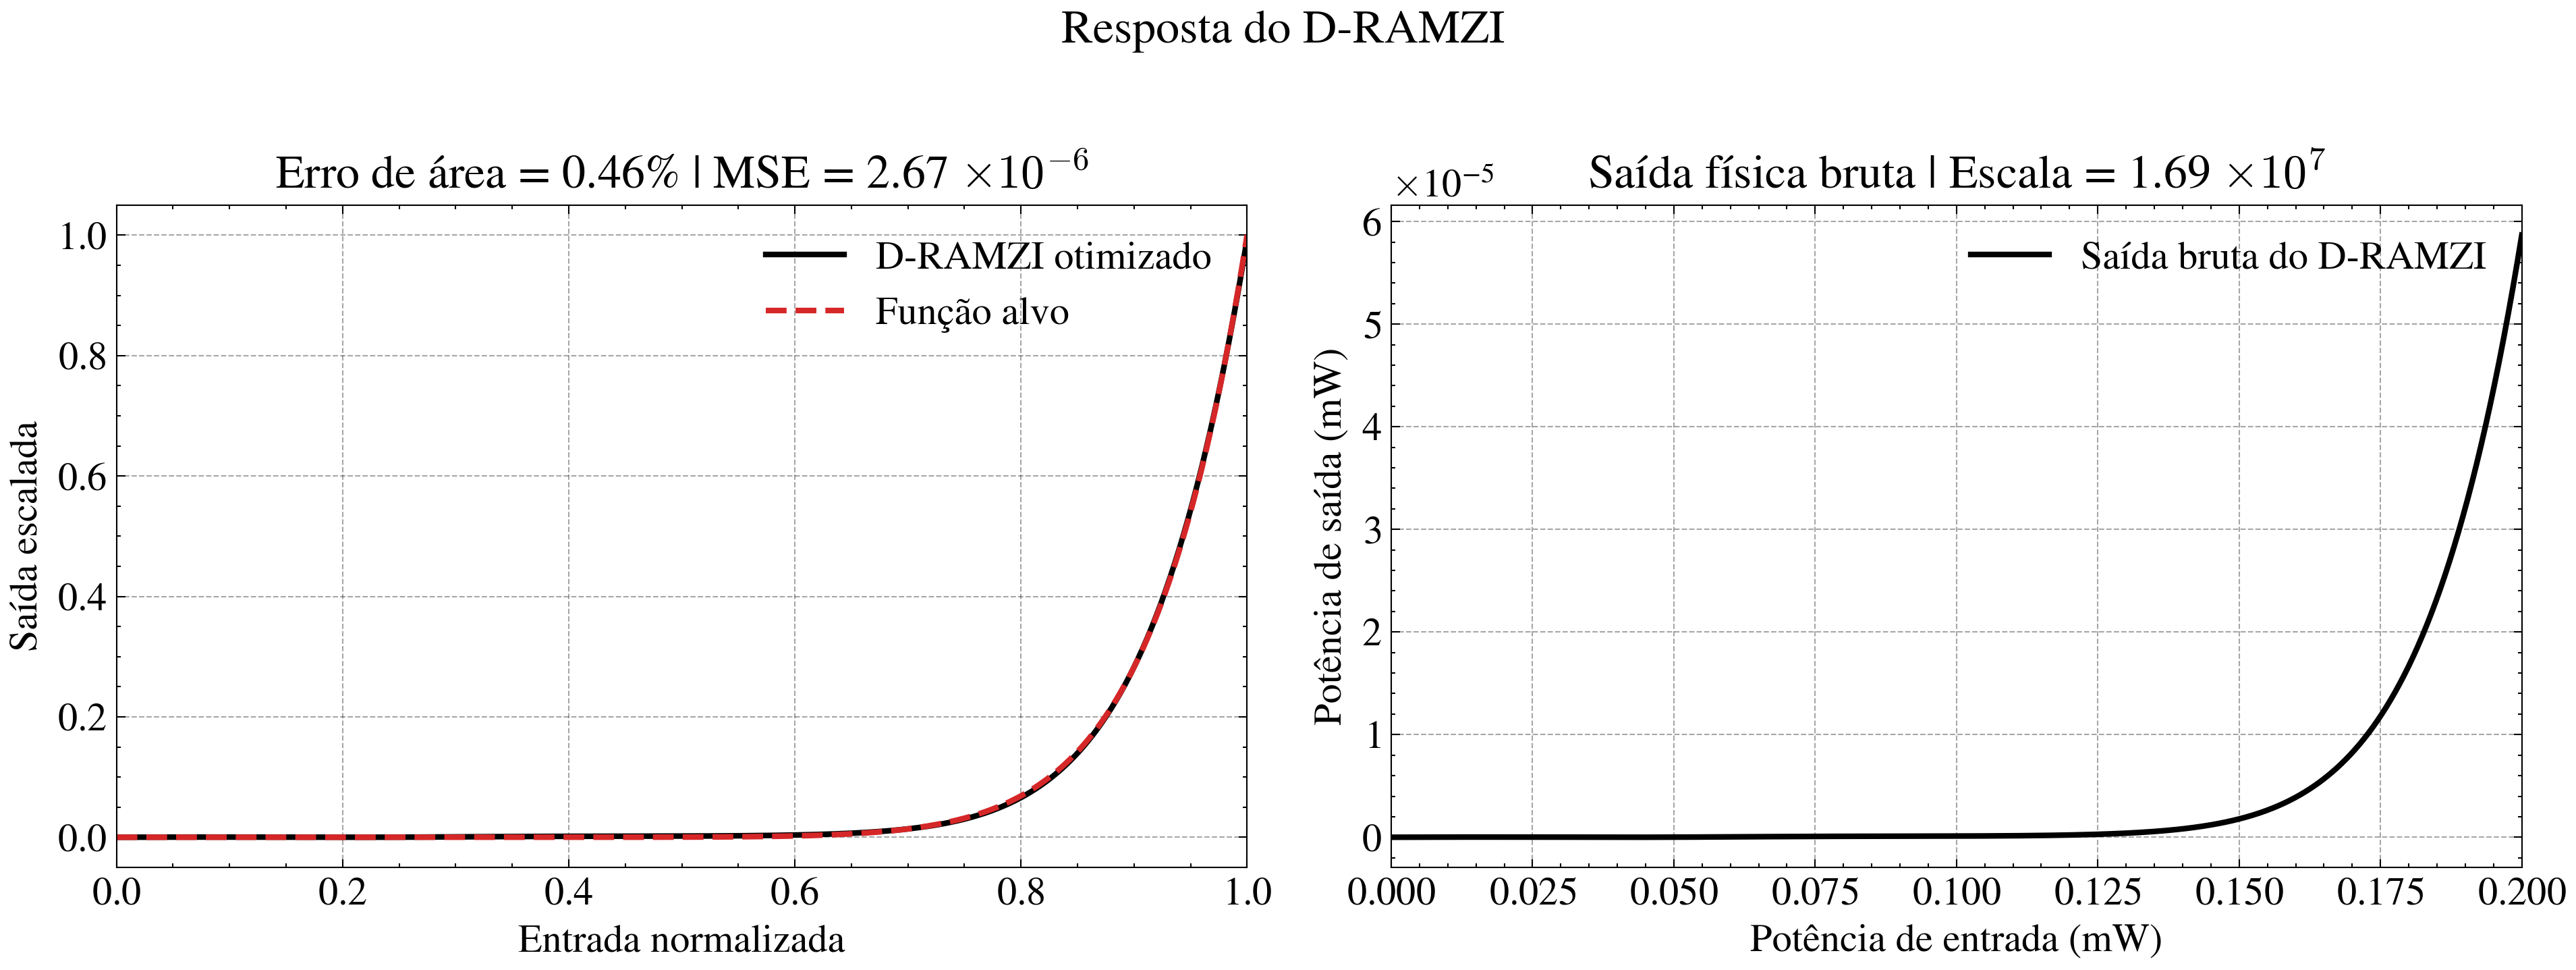

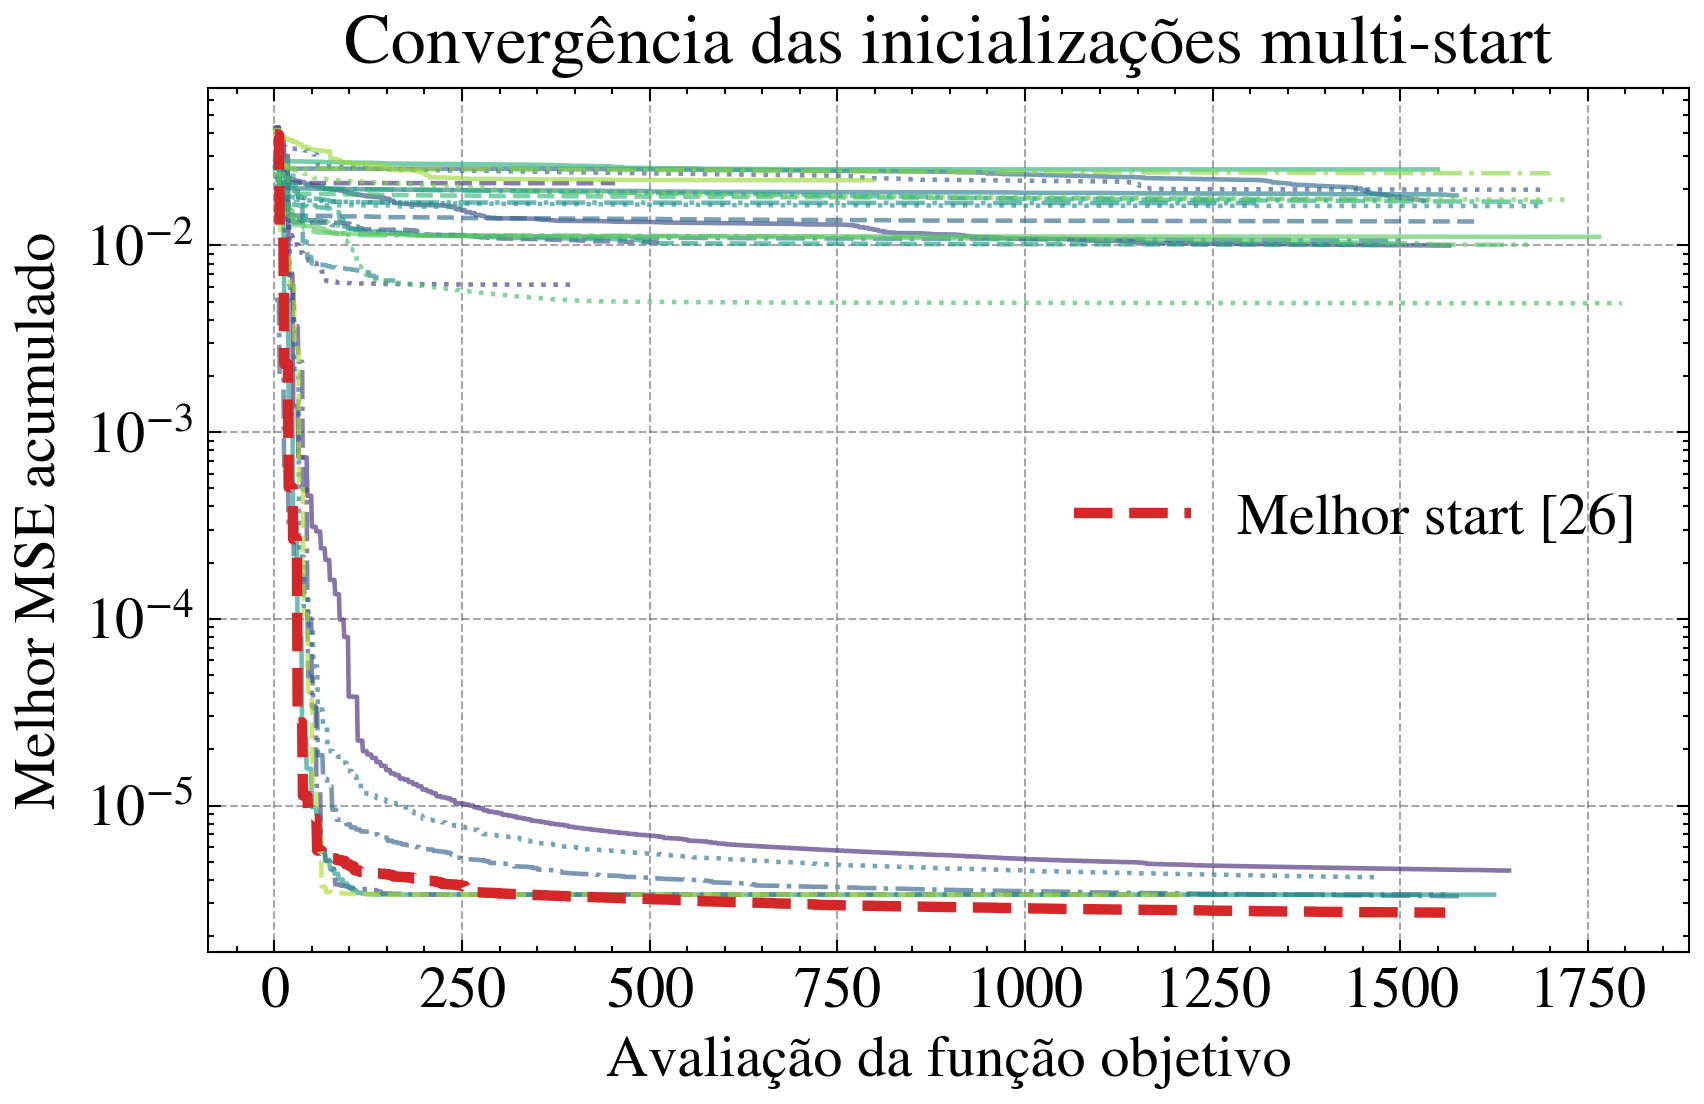

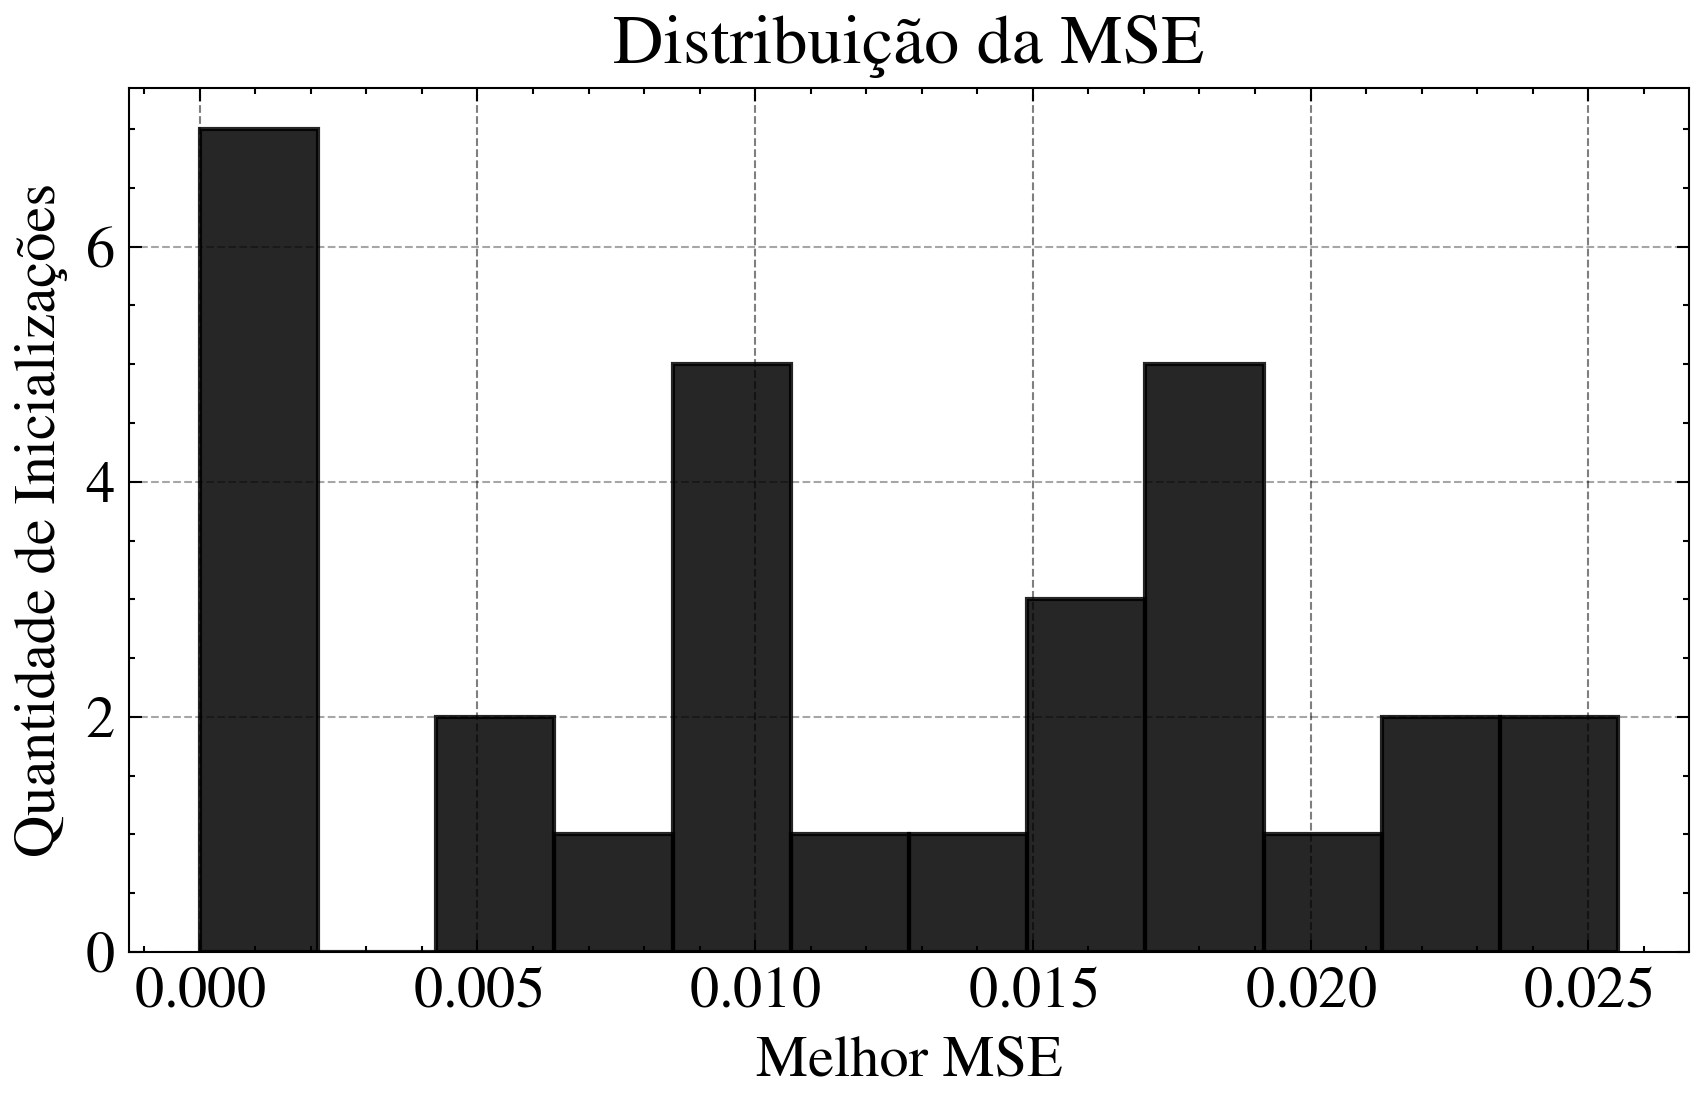

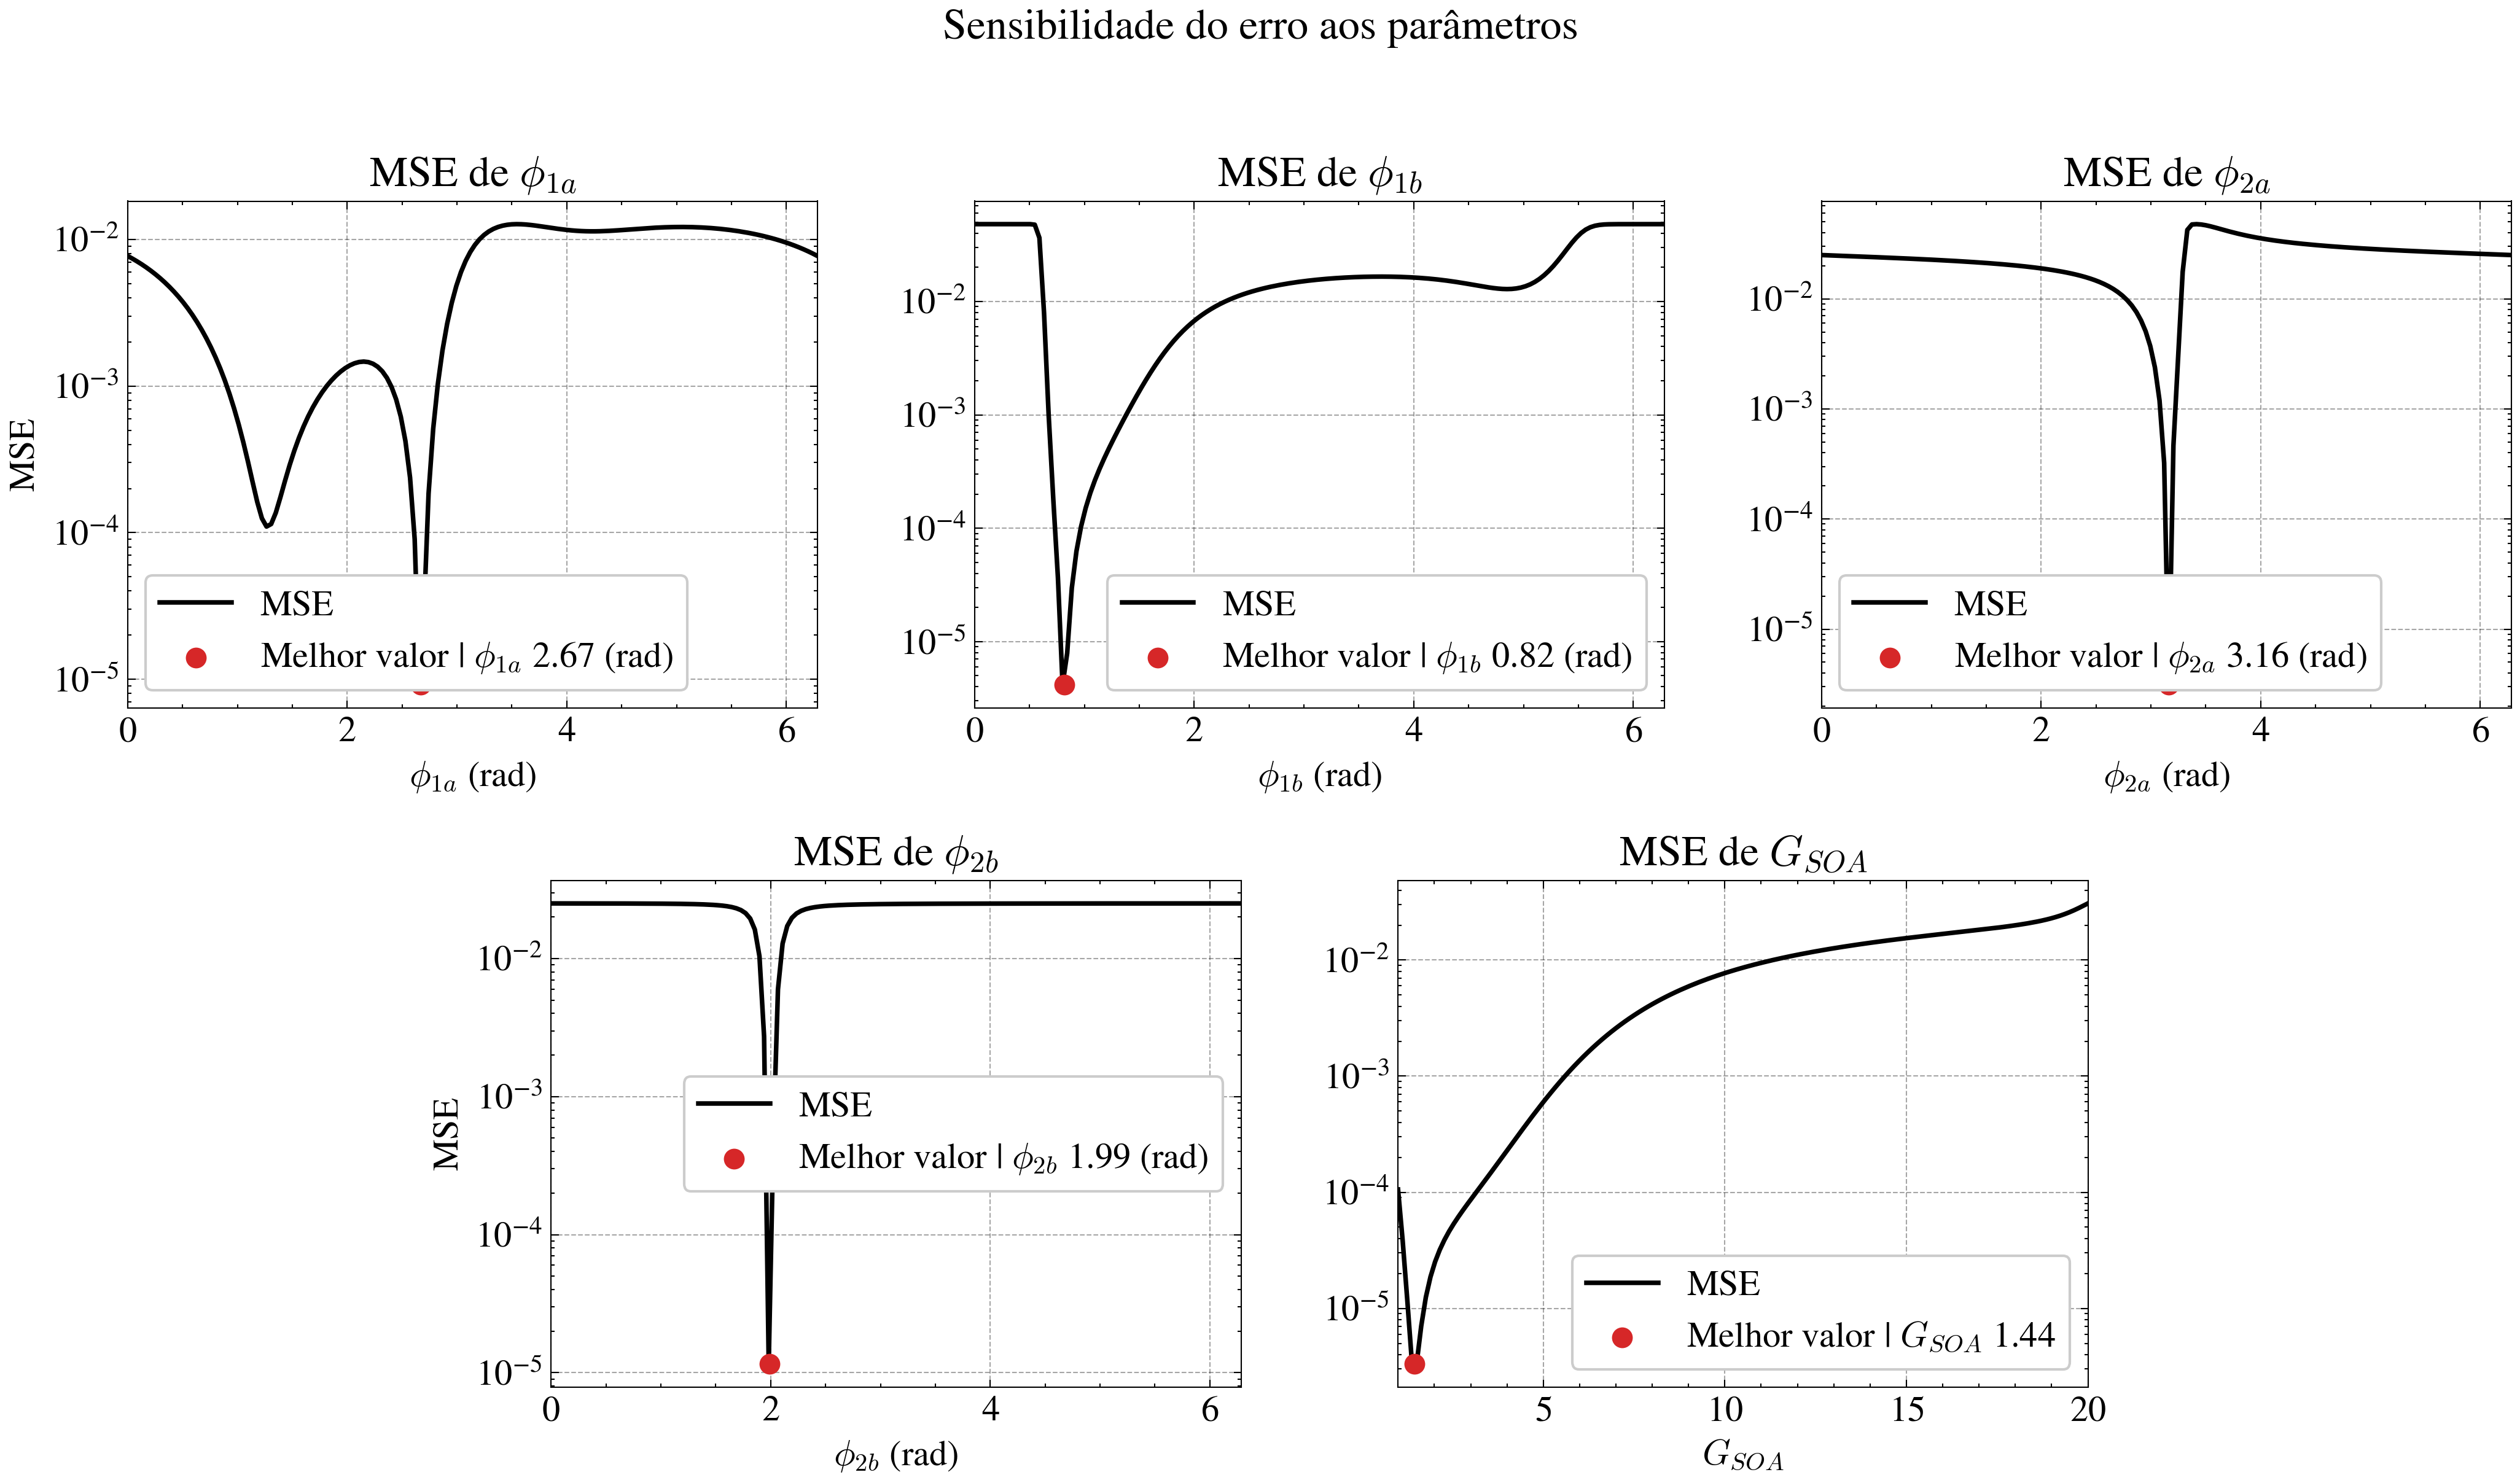


RESULTADOS MULTI-START
MSE final media:   1.14827856e-02
MSE final mediana: 1.08747181e-02
Desvio padrao:     8.06002799e-03
Melhor MSE treino: 2.67246306e-06
Pior MSE treino:   2.55367570e-02
MSE validacao:     2.33605072e-06
MSE antiga valid.: 4.08083374e-06
Tempo total:       14.330 s

Melhores parametros:
  phi_1a   = 2.671205387 rad
  phi_1b   = 0.815283485 rad
  phi_2a   = 3.161220810 rad
  phi_2b   = 1.992235084 rad
  G_SOA    = 1.444719648

Arquivos salvos em: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_trust_region_results


In [27]:
validation_shape_mse, validation_legacy_mse, output_scale = plot_final_curves(best_result.theta_best,best_result.final_mse)
plot_all_histories(results, best_index)
plot_distribution(final_losses)

if RUN_PARAMETER_SENSITIVITY:
    plot_parameter_sensitivity(best_result.theta_best)

print("\n" + "=" * 78)
print("RESULTADOS MULTI-START")
print("=" * 78)
print(f"MSE final media:   {np.mean(final_losses):.8e}")
print(f"MSE final mediana: {np.median(final_losses):.8e}")
print(f"Desvio padrao:     {np.std(final_losses):.8e}")
print(f"Melhor MSE treino: {best_result.final_mse:.8e}")
print(f"Pior MSE treino:   {np.max(final_losses):.8e}")
print(f"MSE validacao:     {validation_shape_mse:.8e}")
print(f"MSE antiga valid.: {validation_legacy_mse:.8e}")
print(f"Tempo total:       {elapsed:.3f} s")

# print("\nTaxas por limiar:")
# for threshold in SUCCESS_THRESHOLDS:
#     count = int(np.sum(final_losses < threshold))
#     percentage = 100.0 * count / N_STARTS
#     print(
#         f"  MSE < {threshold:.0e}: "
#         f"{count}/{N_STARTS} ({percentage:.1f}%)"
#     )

print("\nMelhores parametros:")
for name, value in zip(parameter_names, best_result.theta_best):
    unit = " rad" if name.startswith("phi") else ""
    print(f"  {name:8s} = {value:.9f}{unit}")

save_results(
    results,
    best_result,
    validation_shape_mse,
    validation_legacy_mse,
    output_scale,
    elapsed,
)

print(f"\nArquivos salvos em: {OUTPUT_DIR.resolve()}")